Starting the ML portion...

First model: Logistic Regression using broad labels ("B cell, T cell") and ~2000 genes

In [48]:
import scanpy as sc 
import pandas as pd
from sklearn.metrics import classification_report 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score



adata = sc.read_h5ad("data/annotated_pbmc.h5ad")

In [49]:
X = adata.X
y = adata.obs["cell_type"]
X.shape

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=.2,
    random_state=42,
    stratify=y # assigns labels with the same proportion as the train  y
)

# create the model
model = LogisticRegression(
    max_iter=1000
)
# fit the model to X train and y train, it's learning now
model.fit(X_train, y_train)

# make prediction using X test
y_pred = model.predict(X_test)

# evaluate
accuracy = accuracy_score(y_test, y_pred)
print(f"Model 1 Accuracy: {accuracy:.3f}")

print(adata.shape)
print(X.shape)
print(y.value_counts())
print(X_train.shape)
print(X_test.shape)
print(model.classes_)
print(accuracy_score(y_test, y_pred))

Model 1 Accuracy: 0.964
(2616, 1987)
(2616, 1987)
cell_type
T cell                     1075
Classical monocyte          509
B cell                      338
Memory/effector T cell      247
NK cell                     158
FCGR3A+ monocyte            141
NK/cytotoxic lymphocyte     117
Dendritic/APC                23
Megakaryocyte                 8
Name: count, dtype: int64
(2092, 1987)
(524, 1987)
['B cell' 'Classical monocyte' 'Dendritic/APC' 'FCGR3A+ monocyte'
 'Megakaryocyte' 'Memory/effector T cell' 'NK cell'
 'NK/cytotoxic lymphocyte' 'T cell']
0.9637404580152672


In [50]:
print(classification_report(y_test, y_pred))

                         precision    recall  f1-score   support

                 B cell       1.00      1.00      1.00        68
     Classical monocyte       0.96      0.99      0.98       102
          Dendritic/APC       1.00      0.40      0.57         5
       FCGR3A+ monocyte       0.96      0.96      0.96        28
          Megakaryocyte       1.00      1.00      1.00         2
 Memory/effector T cell       0.91      0.86      0.88        49
                NK cell       0.94      0.97      0.95        32
NK/cytotoxic lymphocyte       0.95      0.78      0.86        23
                 T cell       0.97      1.00      0.98       215

               accuracy                           0.96       524
              macro avg       0.97      0.88      0.91       524
           weighted avg       0.96      0.96      0.96       524



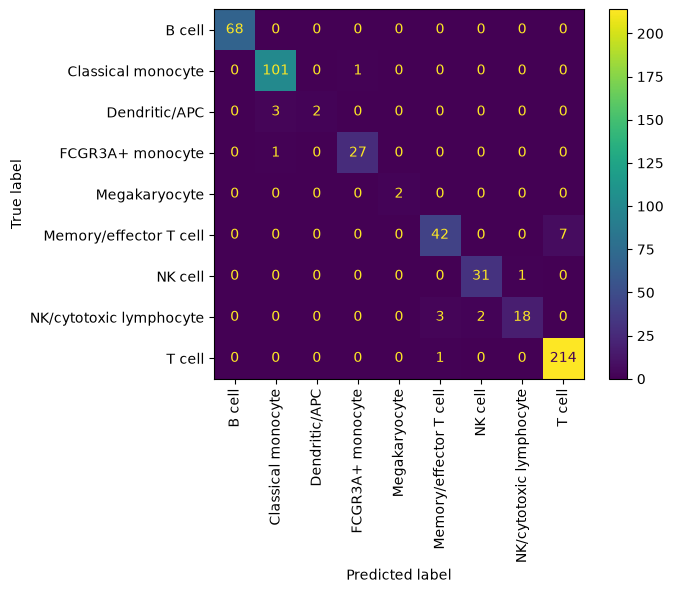

In [51]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(xticks_rotation=90)
plt.show()
# diagonal is the number of cells the model got correct
# off-diagonal shows what was misclassified

The model is confusing T/CD4 T cells with Naive T cells. This first model using 1987 gene features and 2092 cells is giving us 76% accuracy. What would it be if we used the 10 pca features instead? or if we did that with random forest or a pytorch neural network rather than logistic regression? 

Model 2: using 50 pcs to do log reg, meaning instead of using 2000 genes to draw a line of best fit, we use the pcs that capture the most variance instead. There is data leakage, because we found the pcs using test data too, so ignore these results and go to "fixing data leakage" section.

In [52]:
# the pc coordinates are stored here. each row is a cell, and each col is a feature (pc)
# the location of each cell in each pc direction represents their type of gene expression
adata.obsm["X_pca"].shape


(2616, 50)

In [53]:
X_pca10 = adata.obsm["X_pca"][:, :10]
X_pca10.shape

(2616, 10)

In [54]:
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca10, 
    y, 
    test_size=0.2,
    random_state=42, 
    stratify=y
)

In [55]:
model_pca10 = LogisticRegression(
    max_iter=1000
)
model_pca10.fit(X_train_pca, y_train_pca)

y_pred_pca10 = model_pca10.predict(X_test_pca)

accuracy_pca10 = accuracy_score(
    y_test_pca, y_pred_pca10
)
print(f"Model 2 - pca 10 Accuracy: {accuracy_pca10:.3f}")

Model 2 - pca 10 Accuracy: 0.987


Trying all 50 pcs now

In [56]:
X_pca50 = adata.obsm["X_pca"]
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca50, 
    y, 
    test_size=0.2,
    random_state=42, 
    stratify=y
)

model_pca50 = LogisticRegression(
    max_iter=1000
)
model_pca50.fit(X_train_pca, y_train_pca)

y_pred_pca50 = model_pca50.predict(X_test_pca)

accuracy_pca50 = accuracy_score(
    y_test_pca, y_pred_pca50
)
print(f"PCA 50 accuracy: {accuracy_pca50:.3f}")
# the later pcs capture less variation and likely add noise

PCA 50 accuracy: 0.975


Fixing the data leakage: Logistic Regression using 10 pcs with proper split before finding pcs 

In [57]:
# start with original X and y
X = adata.X
y = adata.obs["cell_type"]

# split data before doing pca
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# truncatedSVD is for sparse matrices that gives us pca-like dim reduction
svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

# svd is a model/object that can store the 50pcs and estimate
# train svd with train data then translate into new coordinate system 
X_train_pca = svd.fit_transform(X_train)
X_test_pca = svd.transform(X_test)
# you end up with X test and train in new coordinate system

# just take first 10 pcs
X_train_10 = X_train_pca[:, :10]
X_test_10 = X_test_pca[:, :10]

# train log reg
model_10 = LogisticRegression(max_iter=5000)

model_10.fit(X_train_10, y_train)

y_pred_10 = model_10.predict(X_test_10)

# evaluate
accuracy_10 = accuracy_score(y_test, y_pred_10)

print(f"10-component accuracy: {accuracy_10:.3f}")
print(classification_report(y_test, y_pred_10))

10-component accuracy: 0.990
                         precision    recall  f1-score   support

                 B cell       1.00      1.00      1.00        68
     Classical monocyte       0.98      1.00      0.99       102
          Dendritic/APC       1.00      0.80      0.89         5
       FCGR3A+ monocyte       1.00      0.96      0.98        28
          Megakaryocyte       1.00      1.00      1.00         2
 Memory/effector T cell       1.00      0.98      0.99        49
                NK cell       0.94      1.00      0.97        32
NK/cytotoxic lymphocyte       1.00      0.91      0.95        23
                 T cell       1.00      1.00      1.00       215

               accuracy                           0.99       524
              macro avg       0.99      0.96      0.97       524
           weighted avg       0.99      0.99      0.99       524



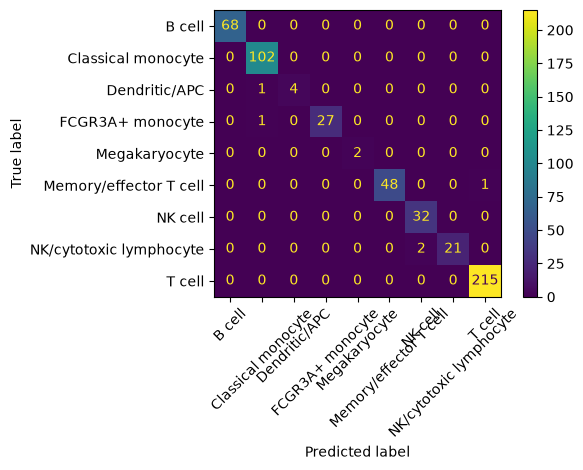

In [58]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_10,
    xticks_rotation=45
)

plt.tight_layout()
plt.show()

Saving the results of each model

In [59]:
model_results = {
    "Logistic regression, 10 SVD components": 0.99
}


Model 2 is Random Forest

In [60]:
# set up the model
rf_model = RandomForestClassifier(
    n_estimators=100, # 100 trees
    random_state=42
)

# train it 
rf_model.fit(
    X_train_10, y_train
)

# evaluate
y_pred_rf = rf_model.predict(X_test_10)

# calculate accuracy
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(f"Random Forest accuracy: {rf_accuracy:.3f}")
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Random Forest accuracy: 0.987
                         precision    recall  f1-score   support

                 B cell       1.00      1.00      1.00        68
     Classical monocyte       0.99      0.99      0.99       102
          Dendritic/APC       1.00      0.80      0.89         5
       FCGR3A+ monocyte       0.97      1.00      0.98        28
          Megakaryocyte       1.00      1.00      1.00         2
 Memory/effector T cell       0.98      0.94      0.96        49
                NK cell       0.97      1.00      0.98        32
NK/cytotoxic lymphocyte       1.00      0.91      0.95        23
                 T cell       0.99      1.00      0.99       215

               accuracy                           0.99       524
              macro avg       0.99      0.96      0.97       524
           weighted avg       0.99      0.99      0.99       524



In [61]:
model_results["Random forest"] = 0.987
print(model_results)

{'Logistic regression, 10 SVD components': 0.99, 'Random forest': 0.987}


A more complicated model didn't improve accuracy, this dataset is linearly separable. RF, which is non linear, didn't add much.


In [62]:
# random forest has a concept, feature importances that tell you which pcs were most useful 
feature_importance = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(10)],
    "importance": rf_model.feature_importances_
})

feature_importance.sort_values(
    "importance",
    ascending=False
)

,PC,importance
2,PC3,0.240095
1,PC2,0.208087
3,PC4,0.206294
5,PC6,0.104662
4,PC5,0.100956
0,PC1,0.073817
7,PC8,0.030984
9,PC10,0.013070
8,PC9,0.011251
6,PC7,0.010784


PCs 2-4 contributed the most, almost 65% of the whole feature importance. Follow up question is, what genes make up these pcs? what genes are the most biologically indicative?

In [63]:
svd.components_.shape

(50, 1987)

In [64]:
svd.components_[2]

array([ 0.02429347,  0.00013067, -0.00124702, ..., -0.00090125,
        0.01455521,  0.02909434], shape=(1987,), dtype=float32)

Making a df just for pc 3 to see which genes affect pc 3 most 

In [65]:
pc3_loadings = pd.DataFrame({
    "gene": adata.var_names,
    "loading": svd.components_[2]
})
pc3_loadings["abs_loading"] = pc3_loadings["loading"].abs()
pc3_loadings.sort_values("abs_loading", ascending=False).head(20)["gene"]

1877        NKG7
636          LTB
654     HLA-DPB1
1598        CCL5
1852       CD79A
646     HLA-DRB1
268         GNLY
653     HLA-DPA1
647     HLA-DQA1
1646       CD79B
546         GZMA
1715        CST7
1872        CD37
648     HLA-DQB1
1317        GZMB
1110        CTSW
1093       MS4A1
1010        PRF1
1007        SRGN
1368       TCL1A
Name: gene, dtype: object

SVD component 3 captures substantial variation in immune-cell expression programs, including cytotoxic lymphocyte, B-cell, and antigen-presentation signatures. Lets look at component 2 and 4:

In [66]:
def get_top_genes(component, n=20):
    loadings = pd.DataFrame({
        "gene": adata.var_names,
        "loading": svd.components_[component]
    })
    
    loadings["abs_loading"] = loadings["loading"].abs()
    
    return loadings.sort_values(
        "abs_loading",
        ascending=False
    ).head(n)

get_top_genes(1).head(20)["gene"]

1714       CST3
636         LTB
129      S100A8
1833     TYROBP
1459       IL32
1116    PTPRCAP
639        AIF1
637        LST1
965        FCN1
1939     LGALS1
158      FCER1G
1966       TYMP
1937     LGALS2
120        CTSS
1598       CCL5
813        SAT1
1877       NKG7
1535      COTL1
370        GPX1
1351       NPC2
Name: gene, dtype: object

Component 2 appears to capture variation associated with myeloid/monocyte identity.

In [67]:
get_top_genes(3).head(20)["gene"]

654     HLA-DPB1
1877        NKG7
653     HLA-DPA1
646     HLA-DRB1
537         IL7R
647     HLA-DQA1
1852       CD79A
1646       CD79B
1459        IL32
268         GNLY
636          LTB
648     HLA-DQB1
1317        GZMB
1715        CST7
1598        CCL5
546         GZMA
1093       MS4A1
1010        PRF1
466       FGFBP2
130       S100A6
Name: gene, dtype: object

So Component 4 appears to capture a broad lymphocyte/immune-state axis, distinguishing populations with different immune expression programs.

In [68]:
# we make a new df using the model's coefs and classes 
# it shows how much each cell type is associated with each pc 
coef_df = pd.DataFrame(
    model_10.coef_,
    index=model_10.classes_,
    columns=[f"Component {i+1}" for i in range(10)]
)

coef_df

,Component 1,Component 2,Component 3,Component 4,Component 5,Component 6,Component 7,Component 8,Component 9,Component 10
B cell,-0.004582,0.058847,-2.248626,0.433672,-0.420242,-0.673275,-0.163391,-0.039930,-0.267722,0.154050
Classical monocyte,0.539508,1.342346,-0.115198,0.035113,0.825038,-0.496246,-0.230115,0.268923,-0.318816,0.166893
Dendritic/APC,0.536477,0.238624,-1.122619,0.382291,-0.202129,-0.726420,0.086457,-1.102250,-0.509530,0.228044
FCGR3A+ monocyte,-0.197152,1.001349,0.141375,-0.363525,-1.302280,0.364650,-0.325333,1.519508,-0.066692,0.103322
Megakaryocyte,0.026084,0.227283,0.090267,-0.028130,-0.170603,0.110400,0.553229,0.199275,0.214781,0.022970
Memory/effector T cell,-0.429876,-0.691688,0.722954,-0.578998,1.171574,1.696385,-0.287800,0.271996,0.441614,0.176174
NK cell,0.355256,-0.447845,1.957420,0.888042,-0.185150,-0.948817,0.506510,0.289778,0.648174,-0.031844
NK/cytotoxic lymphocyte,-0.699752,-1.676053,1.482862,0.801879,0.673402,0.755050,-0.233628,-0.648317,0.170711,-0.899072
T cell,-0.125805,-0.052909,-0.908447,-1.570351,-0.389607,-0.081736,0.094070,-0.758980,-0.312518,0.079461


5-fold cross-validation. We use pipeline, which is an object that allows you to define a sequence of ML steps in order. 

In [69]:
# for each iteration, find 10 SVD components, then run log reg on them
pipeline = Pipeline([
    ("svd", TruncatedSVD(n_components=10, random_state=42)),
    ("logreg", LogisticRegression(max_iter=1000))
])

# split training data into 5 stratified folds 
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# send in the pipeline, training data, and cv to get accuracies for each iteration
cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)
print(cv_scores)
print(f"Mean accuracy: {cv_scores.mean()}")
print("Standard deviation:", cv_scores.std())

[0.97613365 0.96181384 0.97368421 0.97368421 0.97129187]
Mean accuracy: 0.9713215562229506
Standard deviation: 0.004994357501205795


Hyperparameter selection: Now, we test how many components are best to use. 

In [70]:
component_numbers = [5, 10, 20, 30, 50]

results = []

for n in component_numbers:

    pipeline = Pipeline([
        ("svd", TruncatedSVD(
            n_components=n,
            random_state=42
        )),
        ("logreg", LogisticRegression(
            max_iter=1000
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "n_components": n,
        "mean_accuracy": scores.mean(),
        "std_accuracy": scores.std()
    })

results_df = pd.DataFrame(results)

results_df


,n_components,mean_accuracy,std_accuracy
0,5,0.952667,0.009041
1,10,0.971322,0.004994
2,20,0.969886,0.006146
3,30,0.972274,0.004444
4,50,0.967019,0.004627


Performance plateaus around 10–30 components. Increasing dimensionality beyond 10 components does not produce a meaningful improvement in classification performance. The first 10 components captured most of the information needed for this classification task. Let's make the prediction now.

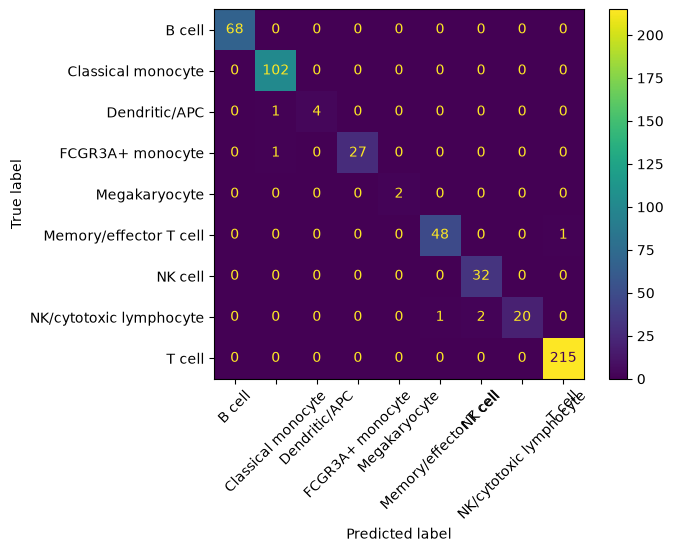

In [71]:
final_model = Pipeline([
    ("svd", TruncatedSVD(
        n_components=10,
        random_state=42
    )),
    ("logreg", LogisticRegression(
        max_iter=1000
    ))
])

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

cm = confusion_matrix(
    y_test, y_pred, labels=final_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_model.classes_
)

disp.plot(
    xticks_rotation=45
)

NK/cytotoxic lymphocyte is being confused with NK cell which is not suprising. FCGR3A+ monocyte is being confused with classical monocyte which is also not suprising. Dendritic/APC is being confused with classical monocyte, which is more concerning but only 1 cell was misclassified. There were only 5 observances of dendritic/APC cells, so the recall is 80%. The result doesn't need to be taken as seriously because there were only 5 cells to observe.

The classifier achieved high overall accuracy, with most errors occurring between biologically related populations, particularly NK/cytotoxic lymphocytes versus NK cells and FCGR3A+ versus classical monocytes. This suggests that the model successfully distinguishes major immune lineages while having greater difficulty resolving closely related subpopulations.

Which individual genes are most useful for distinguishing cell types? Using several genes is more biologically interpretable. You can say that cells can be classified based on their expression in these genes. 


In [72]:
# create a new log reg model 
gene_model = LogisticRegression(
    max_iter=2000,
    C=1.0 # strength of regularization, weak penalty
)

# train and test on gene expression data with 2000 genes as features
gene_model.fit(X_train, y_train)
y_pred_gene = gene_model.predict(X_test)

# evaluate
gene_accuracy = accuracy_score(
    y_test,
    y_pred_gene
)

print(f"Gene-level accuracy: {gene_accuracy:.3f}")

Gene-level accuracy: 0.964


Now we look at gene coefficients to see which genes are most helpful in determining cell type.

In [73]:
gene_model.coef_.shape
# 9 cell type classes, 1987 genes 
# you have a coeff for every gene and cell type class

(9, 1987)

In [74]:
gene_model.coef_

array([[-0.09298658, -0.00315163, -0.0232162 , ..., -0.00025233,
         0.00728357, -0.04197624],
       [-0.00691837,  0.00229276, -0.00654454, ..., -0.00516104,
        -0.00154291, -0.04340971],
       [ 0.03293896,  0.00773816,  0.00868622, ...,  0.01387851,
        -0.01124856,  0.00482932],
       ...,
       [-0.01421507, -0.00220712,  0.0019595 , ..., -0.00079602,
         0.07064804,  0.05299725],
       [-0.04011074,  0.00594643, -0.03380418, ..., -0.00376911,
        -0.07450914,  0.04185942],
       [ 0.14837725, -0.00549081,  0.09266812, ..., -0.01939378,
         0.00772486,  0.07615726]], shape=(9, 1987), dtype=float32)

In [75]:
# make a df of just the B cell coeffs to see what genes drive a cell to be classified as a B cell
bcell_coef = pd.DataFrame({
    "gene": adata.var_names,
    "coefficient": gene_model.coef_[0]
})

# largest coeff tells us it drives it towards B cell a lot
bcell_coef.sort_values(
    "coefficient",
    ascending=False
).head(20)

,gene,coefficient
1852,CD79A,0.409068
1646,CD79B,0.398773
1093,MS4A1,0.340565
654,HLA-DPB1,0.316721
646,HLA-DRB1,0.300169
653,HLA-DPA1,0.259452
648,HLA-DQB1,0.254119
1872,CD37,0.224418
647,HLA-DQA1,0.218097
1405,LINC00926,0.212904


In [76]:
# we look at genes that push away from classifying a cell as B cell
bcell_coef.sort_values(
    "coefficient",
    ascending=True
).head(20)

,gene,coefficient
1459,IL32,-0.204354
1714,CST3,-0.162423
1598,CCL5,-0.148378
1007,SRGN,-0.126200
639,AIF1,-0.112776
130,S100A6,-0.107985
1833,TYROBP,-0.100782
127,S100A11,-0.096523
793,GIMAP4,-0.095857
158,FCER1G,-0.095742


MS4A1, CD79A, CD79B, CD37 are positive coefficients for B cells, so they indicate a cell to be B cell more, relative to the other classes. 
NKG7, GNLY, S100A8, FCN1 are negatve coefficients, so they indicate that they are not B cells. 

A function to see what genes are indicative of each cell type. 

In [77]:
gene_model.classes_

array(['B cell', 'Classical monocyte', 'Dendritic/APC',
       'FCGR3A+ monocyte', 'Megakaryocyte', 'Memory/effector T cell',
       'NK cell', 'NK/cytotoxic lymphocyte', 'T cell'], dtype=object)

In [78]:
# takes in the model, class name, and top n genes 
def top_genes_for_class(model, class_name, n=4):
    # grab index number of the class you want to look at 
    class_index = list(model.classes_).index(class_name)

    # getting coeffs of each gene for the cell type
    coefficients = pd.DataFrame({
        "gene": adata.var_names,
        "coefficient": model.coef_[class_index]
    })

    # return top n coeffs for a particular cell type 
    return coefficients.sort_values(
        "coefficient",
        ascending=False
    ).head(n)

for cell_type in gene_model.classes_:
    print("\n", cell_type)
    print(top_genes_for_class(gene_model, cell_type))


 B cell
          gene  coefficient
1852     CD79A     0.409068
1646     CD79B     0.398773
1093     MS4A1     0.340565
654   HLA-DPB1     0.316721

 Classical monocyte
        gene  coefficient
129   S100A8     0.523721
1937  LGALS2     0.455945
965     FCN1     0.417817
1119   GSTP1     0.301523

 Dendritic/APC
          gene  coefficient
1714      CST3     0.175552
647   HLA-DQA1     0.173251
148     FCER1A     0.160222
490        IGJ     0.144897

 FCGR3A+ monocyte
        gene  coefficient
160   FCGR3A     0.448487
637     LST1     0.312298
1051  IFITM3     0.265675
639     AIF1     0.265611

 Megakaryocyte
          gene  coefficient
494       PPBP     0.088060
493        PF4     0.075979
307       SDPR     0.075937
626  HIST1H2AC     0.075920

 Memory/effector T cell
      gene  coefficient
1598  CCL5     1.007620
545   GZMK     0.645150
1459  IL32     0.272602
537   IL7R     0.232628

 NK cell
        gene  coefficient
268     GNLY     0.510514
1833  TYROBP     0.300543
1317  

Earlier, we discovered top genes for each cluster using rank_gene_groups from scanpy, which was unsupervised. We want to know if the supervised logistic regression is consistent with that, which it is.  

<function matplotlib.pyplot.show(close=None, block=None)>

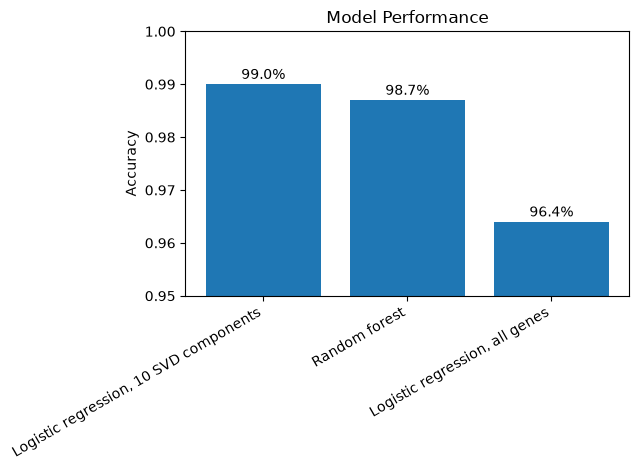

In [91]:
model_results["Logistic regression, all genes"] = 0.964
models = list(model_results.keys())
accuracies = list(model_results.values())
plt.bar(models, accuracies)
plt.ylabel("Accuracy")
plt.title("Model Performance")
plt.ylim(0, 1)

for i, value in enumerate(model_results.values()):
    plt.text(i, value + 0.001, f"{value:.1%}", ha="center")
    
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.ylim(0.95, 1.0)
plt.show

Conclusion:
1. The dataset started with 2700 cells and 32,738 genes. 
2. I used unsupervised clustering to identify 9 cell populations (B cells, T cells, NK cells, classical monocytes, FCGR3A+ monocytes, dendritic/APC, megakaryocytes). I examined each cluster's top marker genes to see that they made sense biologically. 
3. The first model used 10 SVD components and logistic regression, producing an accuracy of 97.1% mean 5-fold cross validation accuracy, and an accuracy of 99% for the test set. 
4. The second model, a more complex model, random forest didn't add much improvement over the linear model. Accuracy was 98.7%. RF did show that components 2-4 were particularly informative. Component 2 mapped to monocyte/myeloid genes such as S100A8, TYROBP, LST1, FCN1. Component 3 mapped to cytotoxic/B-cell/antigen-presentation programs including NKG7, GNLY, CD79A, MS4A1, HLA genes. Component 3 mapped to antigen-presentation and cytotoxic/lymphocyte programs. The confusion matrix showed errors mostly between biologically similar populations. 
5. 